In [1]:
!pip install -q "gymnasium[box2d]" "stable-baselines3[extra]"

In [3]:
import gymnasium as gym
import torch
import numpy as np
import matplotlib.pyplot as plt

from stable_baselines3 import PPO

In [5]:
env = gym.make("LunarLander-v3")

observation, info = env.reset()

In [7]:
labels =[
    "Horizantal position",
    "Horizantal velocity",
    "Vertical position",
    "Vertical velocity",
    "Angle",
    "Angular velocity",
    "Left leg contact",
    "Right leg contact"
]
for name, value in zip(labels, observation):
  print(f"{name}:{value:.3f}")

Horizantal position:0.003
Horizantal velocity:1.414
Vertical position:0.298
Vertical velocity:0.132
Angle:-0.003
Angular velocity:-0.067
Left leg contact:0.000
Right leg contact:0.000


In [8]:
class RocketRewardShaping(gym.Wrapper):

    def __init__(self, env, gamma=0.99):
        super().__init__(env)
        self.gamma = gamma
        self.previous_potential = 0.0

    def potential(self, obs):
        x, y, vx, vy, angle, angular_velocity, left_leg, right_leg = obs

        return -(
            1.5 * abs(x)
            + 0.5 * abs(y)
            + 0.5 * abs(vx)
            + 1.0 * abs(vy)
            + 0.8 * abs(angle)
            + 0.2 * abs(angular_velocity)
        )

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.previous_potential = self.potential(obs)
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)

        current_potential = self.potential(obs)

        shaping_reward = self.gamma * current_potential - self.previous_potential

        self.previous_potential = current_potential

        final_reward = reward + shaping_reward

        return obs, final_reward, terminated, truncated, info

In [9]:
base_env = gym.make("LunarLander-v3")
env = RocketRewardShaping(base_env)

In [11]:
model = PPO("MlpPolicy",
            env,
            learning_rate=0.0003,
            n_steps=2048,
            batch_size=64,
            gamma = 0.99,
            verbose=1)
model.learn(total_timesteps=100000)
model.save("rocket_reward_shaping")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 88       |
|    ep_rew_mean     | -162     |
| time/              |          |
|    fps             | 1269     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 92.1         |
|    ep_rew_mean          | -166         |
| time/                   |              |
|    fps                  | 976          |
|    iterations           | 2            |
|    time_elapsed         | 4            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0058768927 |
|    clip_fraction        | 0.0228       |
|    clip_range           | 0.2          |
|    en

In [13]:
model = PPO.load("rocket_reward_shaping")

print("Trained rocket AI loaded successfully 🚀")

Trained rocket AI loaded successfully 🚀


Episode reward: -53.91


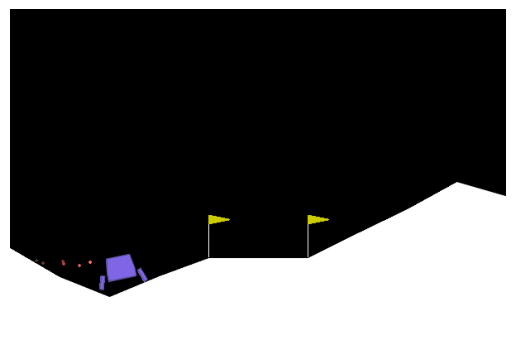

In [14]:
import time
from IPython.display import display, clear_output

play_env = gym.make("LunarLander-v3", render_mode="rgb_array")

obs, info = play_env.reset()
done = False
total_reward = 0

while not done:
    action, _ = model.predict(obs, deterministic=True)

    obs, reward, terminated, truncated, info = play_env.step(action)

    frame = play_env.render()

    display(plt.imshow(frame))
    plt.axis("off")
    clear_output(wait=True)

    total_reward += reward
    done = terminated or truncated

print("Episode reward:", round(total_reward, 2))

play_env.close()

In [17]:
eval_env = gym.make("LunarLander-v3")

successful_landings = 0
scores = []

for episode in range(5):
    print(f"Starting episode {episode + 1}...", flush=True)

    obs, info = eval_env.reset()
    done = False
    total_reward = 0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)

        total_reward += reward
        done = terminated or truncated

    scores.append(total_reward)

    landed = (
        obs[6] == 1 and obs[7] == 1
        and abs(obs[4]) < 0.3
        and abs(obs[2]) < 0.3
        and abs(obs[3]) < 0.3
    )

    if landed:
        successful_landings += 1

    print(f"Episode {episode + 1}: Reward = {total_reward:.2f} | Landed = {landed}", flush=True)

eval_env.close()

print("\nAverage Reward:", round(np.mean(scores), 2))
print("Successful Landings:", successful_landings, "/ 5")
print("Success Rate:", successful_landings * 20, "%")

Starting episode 1...
Episode 1: Reward = 32.56 | Landed = False
Starting episode 2...
Episode 2: Reward = -46.92 | Landed = False
Starting episode 3...
Episode 3: Reward = -96.44 | Landed = True
Starting episode 4...
Episode 4: Reward = -127.93 | Landed = False
Starting episode 5...
Episode 5: Reward = -77.05 | Landed = False

Average Reward: -63.16
Successful Landings: 1 / 5
Success Rate: 20 %


In [19]:
# Recreate the training environment
base_env = gym.make("LunarLander-v3")
env = RocketRewardShaping(base_env)

# Reattach environment to the trained model
model.set_env(env)

# Continue training
model.learn(
    total_timesteps=300_000,
    reset_num_timesteps=False
)

# Save improved model
model.save("rocket_reward_shaping_model_v2")

print("Continued training complete! 🚀")

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 633      |
|    ep_rew_mean     | 28.2     |
| time/              |          |
|    fps             | 1130     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 102400   |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 639          |
|    ep_rew_mean          | 30.7         |
| time/                   |              |
|    fps                  | 929          |
|    iterations           | 2            |
|    time_elapsed         | 4            |
|    total_timesteps      | 104448       |
| train/                  |              |
|    approx_kl            | 0.0043936595 |
|    clip_fraction        | 0.043        |
|    clip_range           | 0.2          |
|    entropy_loss       

In [20]:
eval_env = gym.make("LunarLander-v3")

scores = []
successful_landings = 0

for episode in range(5):
    obs, info = eval_env.reset()
    done = False
    total_reward = 0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)

        total_reward += reward
        done = terminated or truncated

    scores.append(total_reward)

    landed = (
        obs[6] == 1 and obs[7] == 1
        and abs(obs[4]) < 0.3
        and abs(obs[2]) < 0.3
        and abs(obs[3]) < 0.3
    )

    if landed:
        successful_landings += 1

    print(f"Episode {episode + 1}: Reward = {total_reward:.2f} | Landed = {landed}")

eval_env.close()

print("\nAverage Reward:", round(np.mean(scores), 2))
print("Successful Landings:", successful_landings, "/ 5")
print("Success Rate:", successful_landings * 20, "%")

Episode 1: Reward = 170.17 | Landed = True
Episode 2: Reward = -64.88 | Landed = False
Episode 3: Reward = 236.07 | Landed = False
Episode 4: Reward = -177.20 | Landed = False
Episode 5: Reward = -113.49 | Landed = False

Average Reward: 10.14
Successful Landings: 1 / 5
Success Rate: 20 %


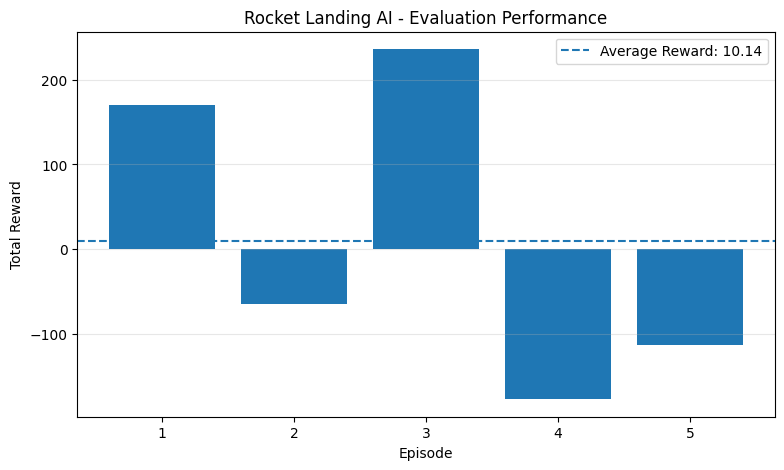

In [21]:
plt.figure(figsize=(9, 5))

episodes = range(1, len(scores) + 1)

plt.bar(episodes, scores)
plt.axhline(y=np.mean(scores), linestyle="--", label=f"Average Reward: {np.mean(scores):.2f}")

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Rocket Landing AI - Evaluation Performance")
plt.xticks(episodes)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

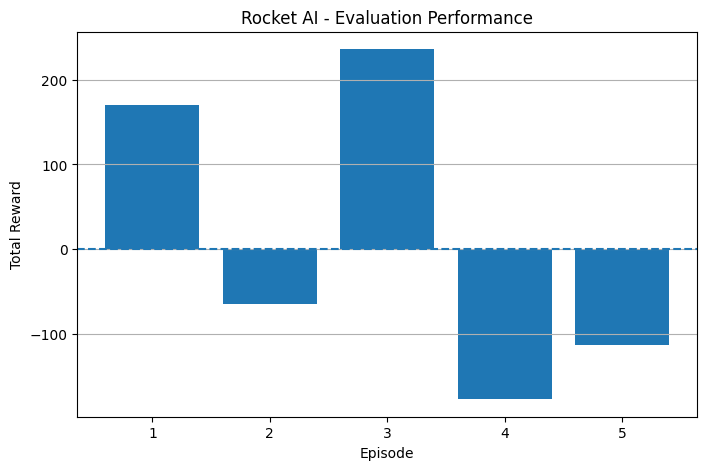

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(range(1, len(scores) + 1), scores)
plt.axhline(0, linestyle="--")

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Rocket AI - Evaluation Performance")

plt.xticks(range(1, len(scores) + 1))
plt.grid(axis="y")
plt.show()